# Experiment 2: High-resolution three-dimensional elasticity

Homogeneous cube $[-1,1]^3$ with $E=1$ and $\nu_{\mathrm P}=0.3$, loaded by a superposition of
three separable oscillatory modes with wavenumbers $\boldsymbol q=\pi(8,9,10)$. On each face the
normal displacement vanishes and the tangential tractions are zero, so the exact solution is
known. Dense ($N\leq24$) and QTT ($N\leq64$) Chebyshev–Galerkin discretizations are compared
with QTT finite differences ($N\leq512$) and Q2/Q4 finite elements in FEniCSx
(Sec. 4.2 and Fig. 5 of the paper).

In [1]:
import numpy as np
import subprocess
import sys
import resource
from time import perf_counter
from typing import Any
from collections import defaultdict
from matplotlib.lines import Line2D
from matplotlib.axes import Axes
from matplotlib.ticker import (
    ScalarFormatter,
    LogFormatterSciNotation,
    LogLocator,
    FuncFormatter,
    NullLocator,
)

from seemps.state import MPS, mps_tensor_product
from seemps.analysis.mesh import RegularInterval, ChebyshevInterval, Mesh
from seemps.analysis.integration import mesh_to_quadrature_mesh
from seemps_galerkin.mps.factories.transform import mpo_chebyshev_transform

from seemps_galerkin.problem import (
    TensorField,
    BoundaryProblem,
    BulkProblem,
    BoundaryFace,
    DirichletBoundaryCondition,
)
from seemps_galerkin.dense.factories import vec_nd_chebyshev_transform
from seemps_galerkin.mps.factories.utils import mps_identity, mps_zeros
from seemps_galerkin.mps.defaults import DEFAULT_SVD_STRATEGY
from seemps_galerkin.mps.linear import AMEnSolver
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp
from seemps_galerkin.fd import solve_mps_bvp_fd
from seemps_galerkin.logger import Logger
from seemps_galerkin.typing import Vector

from tools.data import save_pkl, load_pkl, get_distance_Lp, fresh_process
from tools.plot import set_plot_styles, create_subplots

set_plot_styles()

WAVENUMBERS = np.pi * np.array([8.0, 9.0, 10.0])
WEIGHTS = np.array([1.0, -0.6, 0.3])

κ = np.max(WAVENUMBERS) ** 2
E = 1.0
ν_P = 0.3
λ_1 = E * ν_P / ((1.0 + ν_P) * (1.0 - 2.0 * ν_P))
λ_2 = E / (2.0 * (1.0 + ν_P))

N_range = np.arange(4, 24 + 1, step=2)
n_range = np.arange(2, 6 + 1, step=1)
n_range_fd = np.arange(2, 9 + 1, step=1)

## 1. Dense Chebyshev–Galerkin

Results are stored in `data/2_results_dense.pkl`.

In [2]:
def get_dense_oscillatory_modes(N: int) -> tuple[Mesh, list[Vector]]:
    interval = ChebyshevInterval(-1.0, 1.0, N, endpoints=False)
    mesh = Mesh([interval] * 3)
    x_tensor = mesh.to_tensor(channels_first=True)

    sines = [np.sin(k * x) for k, x in zip(WAVENUMBERS, x_tensor)]
    cosines = [np.cos(k * x) for k, x in zip(WAVENUMBERS, x_tensor)]
    modes = [
        sines[0] * cosines[1] * cosines[2],
        cosines[0] * sines[1] * cosines[2],
        cosines[0] * cosines[1] * sines[2],
    ]

    return mesh, modes


def get_dense_exact_solution(N: int) -> Vector:
    _, modes = get_dense_oscillatory_modes(N)
    k = WAVENUMBERS
    amplitudes = (λ_2 * np.dot(k, k) + κ) * np.eye(3) + (λ_1 + λ_2) * np.outer(k, k)
    a = np.linalg.solve(amplitudes, WEIGHTS)
    return np.concatenate([a[μ] * modes[μ].reshape(-1) for μ in range(3)])


def get_dense_problem(N: int) -> tuple[BulkProblem[Vector], BoundaryProblem[Vector]]:
    d = m = 3
    mesh, modes = get_dense_oscillatory_modes(N)

    # =========================
    # Assemble the bulk problem
    # =========================
    I = np.ones(N**d)

    # Set the principal tensor
    principal = TensorField[Vector]((d, d, m, m), mesh.dimensions)
    for α in range(d):
        for β in range(d):
            for μ in range(m):
                for ν in range(m):
                    c = (
                        λ_1 * (α == μ) * (β == ν)
                        + λ_2 * (α == β) * (μ == ν)
                        + λ_2 * (α == ν) * (β == μ)
                    )
                    if c:
                        principal[α, β, μ, ν] = c * I

    # Set the bulk-reaction tensor
    reaction = TensorField[Vector]((m, m), mesh.dimensions)
    for μ in range(m):
        reaction[μ, μ] = κ * I

    # Set the bulk-load tensor
    source = TensorField[Vector]((m,), mesh.dimensions)
    for μ in range(m):
        source[μ] = WEIGHTS[μ] * modes[μ].reshape(-1)

    bulk = BulkProblem(mesh, principal, reaction, source)

    # =============================
    # Assemble the boundary problem
    # =============================
    zeros = np.zeros(N**2)
    bcs = []
    for dim in range(d):
        for is_left in (True, False):
            face_shape = mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]
            data = TensorField[Vector]((m,), face_shape)
            data[dim] = zeros
            face = BoundaryFace(dim, is_left)
            bcs.append(DirichletBoundaryCondition(face, data))

    boundary = BoundaryProblem(mesh, bcs)

    return bulk, boundary


def get_dense_energy_error(mesh: Mesh, u_num: Vector, u_exact: Vector) -> float:
    m = 3
    N = mesh.dimensions[0]

    # Chebyshev nodes
    x1, _, _ = mesh.to_tensor(channels_first=True)
    x = x1[:, 0, 0]

    # Spectral differentiation matrix
    dx = x[:, None] - x[None, :]
    np.fill_diagonal(dx, 1.0)
    w = 1.0 / np.prod(dx, axis=1)

    D = (w[None, :] / w[:, None]) / dx
    np.fill_diagonal(D, 0.0)
    np.fill_diagonal(D, -D.sum(axis=1))

    # Quadrature weights
    qmesh = mesh_to_quadrature_mesh(mesh)
    q1, q2, q3 = qmesh.to_tensor(channels_first=True)
    weights = q1 * q2 * q3

    def energy_squared(u: np.ndarray) -> float:
        u = u.reshape(m, N, N, N)
        grad = np.empty((m, 3, N, N, N))
        for α in range(3):
            v = np.moveaxis(u, α + 1, -1)
            dv = v @ D.T
            grad[:, α] = np.moveaxis(dv, -1, α + 1)

        div = sum(grad[μ, μ] for μ in range(m))
        strain = 0.5 * (grad + np.swapaxes(grad, 0, 1))
        density = (
            λ_1 * div**2 + 2.0 * λ_2 * np.sum(strain**2, axis=(0, 1)) + κ * np.sum(u**2, axis=0)
        )
        return float(np.sum(weights * density))

    error = u_num - u_exact

    return float(np.sqrt(energy_squared(error) / energy_squared(u_exact)))

In [3]:
@fresh_process()
def run_dense(N: int) -> dict[str, Any]:
    tick = perf_counter()
    bulk, boundary = get_dense_problem(N)
    u_cheb = solve_dense_bvp(bulk, boundary)
    time = perf_counter() - tick

    memory = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2  # in GiB

    u_num = vec_nd_chebyshev_transform(
        u_cheb, (3, N, N, N), which_dimensions=(1, 2, 3), inverse=True
    )
    u_exact = get_dense_exact_solution(N)
    error_L2 = get_distance_Lp(u_exact, u_num, p=2.0, relative=True)
    error_energy = get_dense_energy_error(bulk.mesh, u_num, u_exact)
    return {"time": time, "memory": memory, "error_L2": error_L2, "error_energy": error_energy}


try:
    results_dense = load_pkl("data/2_results_dense.pkl")
except FileNotFoundError:
    results_dense = defaultdict(list)
    for N in N_range:
        data = run_dense(int(N))
        print(f"Dense N={N}: {data}")
        for key, value in data.items():
            results_dense[key].append(value)
    save_pkl(dict(results_dense), "data/2_results_dense.pkl")

## 2. QTT Chebyshev–Galerkin

Results are stored in `data/2_results_mps_cg.pkl`.

In [4]:
SVD_STRATEGY = DEFAULT_SVD_STRATEGY
SOLVER = AMEnSolver(preconditioner="block_jacobi")

In [5]:
def get_mps_oscillatory_modes(n: int) -> tuple[Mesh, list[MPS]]:
    N = 2**n
    interval = ChebyshevInterval(-1.0, 1.0, N, endpoints=False)
    x = interval.to_vector()
    mesh = Mesh([interval] * 3)

    ψ_sines = []
    ψ_cosines = []
    for k in WAVENUMBERS:
        ψ_sin = MPS.from_vector(np.sin(k * x), [2] * n, normalize=False, strategy=SVD_STRATEGY)
        ψ_cos = MPS.from_vector(np.cos(k * x), [2] * n, normalize=False, strategy=SVD_STRATEGY)
        ψ_sines.append(ψ_sin)
        ψ_cosines.append(ψ_cos)

    ψ_modes = [
        mps_tensor_product([ψ_sines[0], ψ_cosines[1], ψ_cosines[2]]),
        mps_tensor_product([ψ_cosines[0], ψ_sines[1], ψ_cosines[2]]),
        mps_tensor_product([ψ_cosines[0], ψ_cosines[1], ψ_sines[2]]),
    ]

    return mesh, ψ_modes


def get_mps_problem(n: int) -> tuple[BulkProblem[MPS], BoundaryProblem[MPS]]:
    d = m = 3
    mesh, ψ_modes = get_mps_oscillatory_modes(n)

    # =========================
    # Assemble the bulk problem
    # =========================
    I = mps_identity(d * n)

    # Set the principal tensor
    principal = TensorField[MPS]((d, d, m, m), mesh.dimensions)
    for α in range(d):
        for β in range(d):
            for μ in range(m):
                for ν in range(m):
                    c = (
                        λ_1 * (α == μ) * (β == ν)
                        + λ_2 * (α == β) * (μ == ν)
                        + λ_2 * (α == ν) * (β == μ)
                    )
                    if c:
                        principal[α, β, μ, ν] = c * I

    # Set the bulk-reaction tensor
    reaction = TensorField[MPS]((m, m), mesh.dimensions)
    for μ in range(m):
        reaction[μ, μ] = κ * I

    # Set the bulk-load tensor
    source = TensorField[MPS]((m,), mesh.dimensions)
    for μ in range(m):
        source[μ] = WEIGHTS[μ] * ψ_modes[μ]

    bulk = BulkProblem(mesh, principal, reaction, source)

    # =============================
    # Assemble the boundary problem
    # =============================
    zeros = mps_zeros(n * (d - 1))
    bcs = []
    for dim in range(d):
        for is_left in (True, False):
            face_shape = mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]
            data = TensorField[MPS]((m,), face_shape)
            data[dim] = zeros
            face = BoundaryFace(dim, is_left)
            bcs.append(DirichletBoundaryCondition(face, data))

    boundary = BoundaryProblem(mesh, bcs)

    return bulk, boundary

In [6]:
@fresh_process()
def run_mps(n: int) -> dict[str, Any]:
    tick = perf_counter()
    bulk, boundary = get_mps_problem(n)

    Logger.activate(level=0, collect=True)
    try:
        ψ_u_cheb = solve_mps_bvp(
            bulk,
            boundary,
            strategy=SVD_STRATEGY,
            solver=SOLVER,
        )
        time = perf_counter() - tick
        maxbond_A = max(Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1])
        maxbond_b = max(Logger.sink["solve.mps.b_dirichlet.bond_dimensions"][-1])
    finally:
        Logger.deactivate()
        Logger.clear()

    memory = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

    ψ_u_num = ψ_u_cheb
    for α in range(3):
        transform = mpo_chebyshev_transform(n, inverse=True, strategy=SVD_STRATEGY).extend(
            ψ_u_num.size,
            sites=list(range(1 + α * n, 1 + (α + 1) * n)),
            dimensions=[3] + [2] * (2 * n),
        )
        ψ_u_num = transform.apply(ψ_u_num)

    u_num = np.real_if_close(ψ_u_num.to_vector())
    u_exact = get_dense_exact_solution(2**n)

    return {
        "n": n,
        "time": time,
        "memory": memory,
        "maxbond_A": maxbond_A,
        "maxbond_b": maxbond_b,
        "maxbond_u": ψ_u_cheb.max_bond_dimension(),
        "error_L2": get_distance_Lp(u_exact, u_num, p=2.0, relative=True),
        "error_energy": get_dense_energy_error(bulk.mesh, u_num, u_exact),
    }


try:
    results_mps = load_pkl("data/2_results_mps_cg.pkl")
except FileNotFoundError:
    results_mps = defaultdict(list)
    for n in n_range:
        data = run_mps(int(n))
        print(f"n={n}, data={data}")
        for key, value in data.items():
            results_mps[key].append(value)

        save_pkl(dict(results_mps), "data/2_results_mps_cg.pkl")


## 3. QTT finite differences

Results are stored in `data/2_results_mps_fd.pkl`.

In [7]:
def get_mps_problem_fd(n: int) -> tuple[BulkProblem[MPS], BoundaryProblem[MPS], Vector]:
    N = 2**n
    interval = RegularInterval(-1.0, 1.0, N, endpoint_right=True)
    mesh, x = Mesh([interval] * 3), interval.to_vector()
    ψ_sin = [
        MPS.from_vector(np.sin(k * x), [2] * n, normalize=False, strategy=SVD_STRATEGY)
        for k in WAVENUMBERS
    ]
    ψ_cos = [
        MPS.from_vector(np.cos(k * x), [2] * n, normalize=False, strategy=SVD_STRATEGY)
        for k in WAVENUMBERS
    ]
    ψ_modes = [
        mps_tensor_product([ψ_sin[0], ψ_cos[1], ψ_cos[2]]),
        mps_tensor_product([ψ_cos[0], ψ_sin[1], ψ_cos[2]]),
        mps_tensor_product([ψ_cos[0], ψ_cos[1], ψ_sin[2]]),
    ]
    bulk_cg, boundary_cg = get_mps_problem(n)
    source = TensorField[MPS]((3,), mesh.dimensions)
    for μ in range(3):
        source[μ] = WEIGHTS[μ] * ψ_modes[μ]
    amplitudes = (λ_2 * np.dot(WAVENUMBERS, WAVENUMBERS) + κ) * np.eye(3) + (λ_1 + λ_2) * np.outer(
        WAVENUMBERS, WAVENUMBERS
    )
    a = np.linalg.solve(amplitudes, WEIGHTS)
    exact = np.concatenate([a[μ] * ψ_modes[μ].to_vector() for μ in range(3)])
    return (
        BulkProblem(mesh, bulk_cg.principal, bulk_cg.reaction, source),
        BoundaryProblem(mesh, boundary_cg.boundary_conditions),
        exact,
    )


def get_fd_energy_error(u_num: Vector, u_exact: Vector, N: int) -> float:
    h = 2.0 / (N - 1)
    q = np.ones(N)
    q[[0, -1]] = 0.5
    weights = h**3 * q[:, None, None] * q[None, :, None] * q[None, None, :]

    def energy_squared(u: Vector) -> float:
        u = u.reshape(3, N, N, N)
        grad = np.stack([np.gradient(u, h, axis=α + 1, edge_order=2) for α in range(3)], axis=1)
        div = sum(grad[μ, μ] for μ in range(3))
        strain = 0.5 * (grad + np.swapaxes(grad, 0, 1))
        density = (
            λ_1 * div**2 + 2.0 * λ_2 * np.sum(strain**2, axis=(0, 1)) + κ * np.sum(u**2, axis=0)
        )
        return float(np.sum(weights * density))

    return float(np.sqrt(energy_squared(u_num - u_exact) / energy_squared(u_exact)))


@fresh_process()
def run_mps_fd(n: int) -> dict[str, Any]:
    tick = perf_counter()
    bulk, boundary, u_exact = get_mps_problem_fd(n)
    Logger.activate(level=0, collect=True)
    try:
        ψ_u = solve_mps_bvp_fd(bulk, boundary, strategy=SVD_STRATEGY, solver=SOLVER)
        time = perf_counter() - tick
        maxbond_A = max(Logger.sink["solve.mps.A.bond_dimensions"][-1])
        maxbond_b = max(Logger.sink["solve.mps.b.bond_dimensions"][-1])
    finally:
        Logger.deactivate()
        Logger.clear()
    u_num = np.real_if_close(ψ_u.to_vector())
    N = 2**n
    return {
        "n": n,
        "time": time,
        "memory": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2,
        "maxbond_A": maxbond_A,
        "maxbond_b": maxbond_b,
        "maxbond_u": ψ_u.max_bond_dimension(),
        "error_L2": get_distance_Lp(u_exact, u_num, p=2.0, relative=True),
        "error_energy": get_fd_energy_error(u_num, u_exact, N),
    }


try:
    results_mps_fd = load_pkl("data/2_results_mps_fd.pkl")
except FileNotFoundError:
    results_mps_fd = defaultdict(list)

    for n in n_range_fd:
        data = run_mps_fd(int(n))
        print(f"n={n}, data={data}")
        for key, value in data.items():
            results_mps_fd[key].append(value)
    results_mps_fd = dict(results_mps_fd)
    save_pkl(results_mps_fd, "data/2_results_mps_fd.pkl")

## 4. FEniCSx finite elements

Computed by `2_3d_high_resolution_fenicsx.py` inside Docker, with the image built from
`../packages/fenicsx.Dockerfile`. Results are stored in `data/2_results_fenicsx.pkl`.

In [8]:
try:
    results_fenicsx = load_pkl("data/2_results_fenicsx.pkl")
except FileNotFoundError:
    subprocess.run([sys.executable, "2_3d_high_resolution_fenicsx.py"], check=True)
    results_fenicsx = load_pkl("data/2_results_fenicsx.pkl")
results_fenicsx_Q2 = results_fenicsx[2]
results_fenicsx_Q4 = results_fenicsx[4]

## 5. Figures

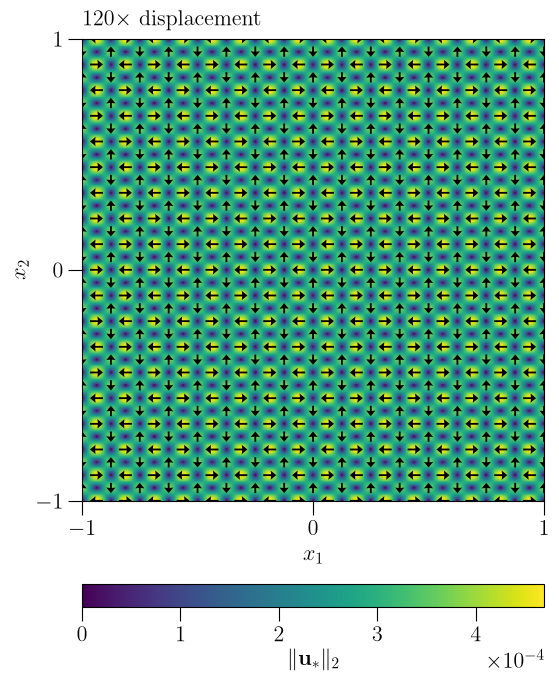

In [9]:
def plot_solution_slice(N: int, ax: Axes, ax_colorbar: Axes):
    x = np.linspace(-1.0, 1.0, N)
    X, Y = np.meshgrid(x, x, indexing="xy")

    k = WAVENUMBERS
    amplitudes = (λ_2 * np.dot(k, k) + κ) * np.eye(3) + (λ_1 + λ_2) * np.outer(k, k)
    a = np.linalg.solve(amplitudes, WEIGHTS)

    # Exact displacement at z = 0
    u = np.array(
        [
            a[0] * np.sin(k[0] * X) * np.cos(k[1] * Y),
            a[1] * np.cos(k[0] * X) * np.sin(k[1] * Y),
            np.zeros_like(X),
        ]
    )
    modulus = np.linalg.norm(u, axis=0)

    # Plot displacement magnitude
    image = ax.imshow(
        modulus,
        extent=(-1, 1, -1, 1),
        origin="lower",
        interpolation="none",
        resample=False,
        aspect="equal",
    )

    # Plot displacement vectors at oscillation maxima
    x_cos = np.linspace(-1.0, 1.0, 2 * 8 + 1)
    y_cos = np.linspace(-1.0, 1.0, 2 * 9 + 1)
    x_sin = 0.5 * (x_cos[:-1] + x_cos[1:])
    y_sin = 0.5 * (y_cos[:-1] + y_cos[1:])
    X1, Y1 = np.meshgrid(x_sin, y_cos, indexing="xy")
    X2, Y2 = np.meshgrid(x_cos, y_sin, indexing="xy")
    Xq = np.concatenate([X1.ravel(), X2.ravel()])
    Yq = np.concatenate([Y1.ravel(), Y2.ravel()])
    Uq = a[0] * np.sin(k[0] * Xq) * np.cos(k[1] * Yq)
    Vq = a[1] * np.cos(k[0] * Xq) * np.sin(k[1] * Yq)

    arrow_magnification = 120.0
    ax.quiver(
        Xq,
        Yq,
        arrow_magnification * Uq,
        arrow_magnification * Vq,
        angles="xy",
        scale_units="xy",
        scale=1,
        color="black",
        pivot="mid",
        width=0.004,
        headwidth=5,
        headlength=3,
        headaxislength=2.8,
        zorder=2.0,
    )

    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")

    ax.text(
        0.0,
        1.02,
        rf"${arrow_magnification:g}\times$ displacement",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
    )

    # Horizontal scientific-notation colorbar
    colorbar = ax.figure.colorbar(
        image,
        cax=ax_colorbar,
        orientation="horizontal",
    )
    colorbar.set_label(r"$\|\mathbf{u}_*\|_2$", labelpad=2)

    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0, 0))
    colorbar.formatter = formatter
    colorbar.update_ticks()

    return image


fig, axs = create_subplots(width_px=1000, height_px=600)
ax = axs[0, 0]

ax_colorbar = ax.inset_axes((0.0, -0.23, 1.0, 0.05))
plot_solution_slice(N=1024, ax=ax, ax_colorbar=ax_colorbar)
fig.savefig("figures/2_displacement.pdf", dpi=600, bbox_inches="tight")

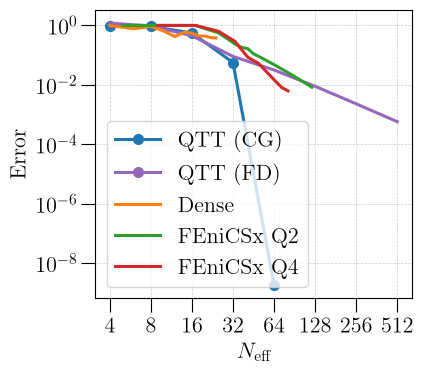

In [10]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]

ax.plot(2**n_range, results_mps["error_L2"], "-o", color="C0")
ax.plot(2**n_range_fd, results_mps_fd["error_L2"], "-", color="tab:purple")
ax.plot(N_range, results_dense["error_L2"], "-", color="C1")
ax.plot(results_fenicsx_Q2["N_eff"], results_fenicsx_Q2["error_L2"], "-", color="C2")
ax.plot(results_fenicsx_Q4["N_eff"], results_fenicsx_Q4["error_L2"], "-", color="C3")
ax.grid(True, which="both")
ax.set_xscale("log")
ax.set_xticks(2**n_range_fd)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_yscale("log")
ax.set_xlabel(r"$N_{\mathrm{eff}}$")
ax.set_ylabel("Error")

handles_1 = [
    Line2D([0], [0], color="C0", marker="o", label="QTT (CG)"),
    Line2D([0], [0], color="tab:purple", marker="o", label="QTT (FD)"),
    Line2D([0], [0], color="C1", label="Dense"),
    Line2D([0], [0], color="C2", label=r"FEniCSx Q2"),
    Line2D([0], [0], color="C3", label=r"FEniCSx Q4"),
]
ax.legend(handles=handles_1, loc="lower left")
fig.tight_layout()
fig.savefig("figures/2_error_N.pdf", dpi=300)

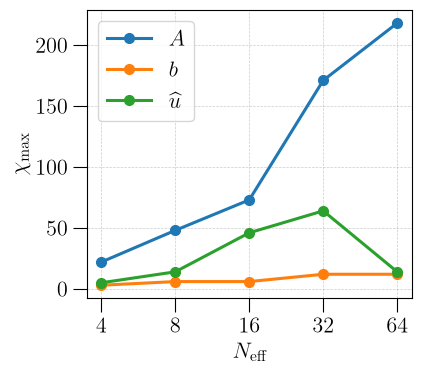

In [11]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]

ax.plot(2**n_range, results_mps["maxbond_A"], "-o", label=r"$A$")  # type: ignore
ax.plot(2**n_range, results_mps["maxbond_b"], "-o", label=r"$b$")  # type: ignore
ax.plot(2**n_range, results_mps["maxbond_u"], "-o", label=r"$\widehat{u}$")  # type: ignore
ax.legend()
ax.grid(True, which="both")
ax.set_xscale("log")
ax.set_xticks(2**n_range)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel(r"$N_{\mathrm{eff}}$")
ax.set_ylabel(r"$\chi_{\max}$")
fig.tight_layout()
fig.savefig("figures/2_maxbond_N.pdf", dpi=300)

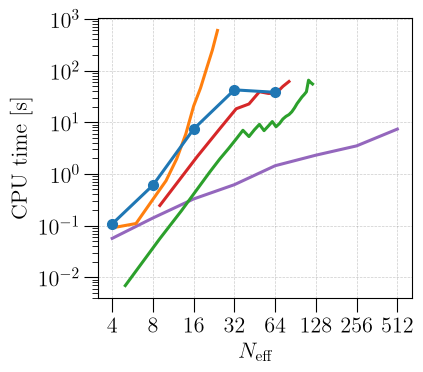

In [12]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]
ax.plot(2**n_range, results_mps["time"], "-o", color="C0", zorder=10)
ax.plot(2**n_range_fd, results_mps_fd["time"], color="tab:purple")
ax.plot(N_range, results_dense["time"], "-", color="C1")
ax.plot(results_fenicsx_Q2["N_eff"], results_fenicsx_Q2["time"], "-", color="C2")
ax.plot(results_fenicsx_Q4["N_eff"], results_fenicsx_Q4["time"], "-", color="C3")
ax.grid(True)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(2**n_range_fd)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel(r"$N_{\mathrm{eff}}$")
ax.set_ylabel("CPU time [s]")
fig.tight_layout()
fig.savefig("figures/2_times_N.pdf", dpi=300)

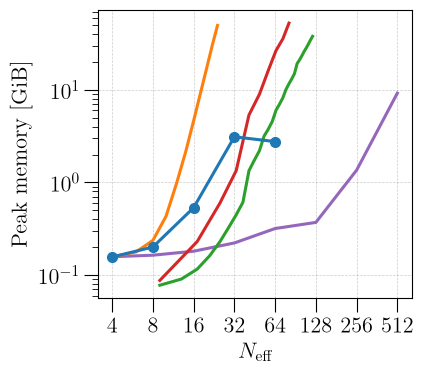

In [13]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]
ax.plot(2**n_range, results_mps["memory"], "-o", color="C0", zorder=10)
ax.plot(2**n_range_fd, results_mps_fd["memory"], color="tab:purple")
ax.plot(N_range, results_dense["memory"], color="C1")
ax.plot(results_fenicsx_Q2["N_eff"][1:], results_fenicsx_Q2["memory"][1:], color="C2")
ax.plot(results_fenicsx_Q4["N_eff"], results_fenicsx_Q4["memory"], color="C3")
ax.grid(True)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(2**n_range_fd)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel(r"$N_{\mathrm{eff}}$")
ax.set_ylabel("Peak memory [GiB]")
fig.tight_layout()
fig.savefig("figures/2_memory_N.pdf", dpi=300)

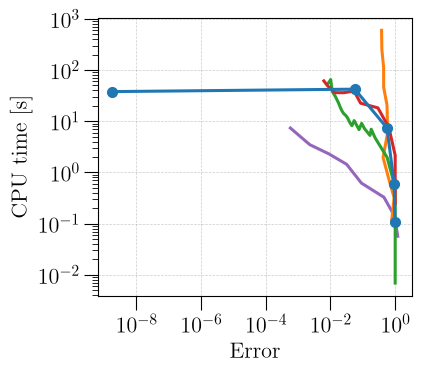

In [14]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]
ax.plot(results_mps["error_L2"], results_mps["time"], "-o", zorder=10)
ax.plot(results_mps_fd["error_L2"], results_mps_fd["time"], color="tab:purple")
ax.plot(results_dense["error_L2"], results_dense["time"])
ax.plot(results_fenicsx_Q2["error_L2"], results_fenicsx_Q2["time"], "-", color="C2")
ax.plot(results_fenicsx_Q4["error_L2"], results_fenicsx_Q4["time"], "-", color="C3")
ax.grid(True)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,), numticks=6))
ax.xaxis.set_major_formatter(LogFormatterSciNotation(base=10))
ax.set_xlabel("Error")
ax.set_ylabel("CPU time [s]")
fig.tight_layout()
fig.savefig("figures/2_benchmark.pdf", dpi=300)

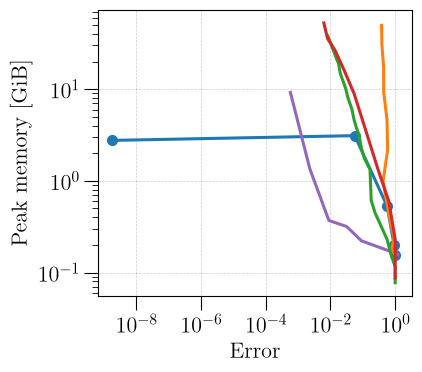

In [15]:
fig, axs = create_subplots(width_px=450)
ax = axs[0, 0]
ax.plot(results_mps["error_L2"], results_mps["memory"], "-o", color="C0")
ax.plot(results_mps_fd["error_L2"], results_mps_fd["memory"], color="tab:purple")
ax.plot(results_dense["error_L2"], results_dense["memory"], color="C1")
ax.plot(results_fenicsx_Q2["error_L2"][1:], results_fenicsx_Q2["memory"][1:], color="C2")
ax.plot(results_fenicsx_Q4["error_L2"], results_fenicsx_Q4["memory"], color="C3")
ax.grid(True)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,), numticks=6))
ax.xaxis.set_major_formatter(LogFormatterSciNotation(base=10))
ax.set_xlabel(r"Error")
ax.set_ylabel("Peak memory [GiB]")
fig.tight_layout()
fig.savefig("figures/2_memory_benchmark.pdf", dpi=300)